<a href="https://colab.research.google.com/github/erikarahmadinaaa01/202431176_Erika-Rahmadina_F/blob/main/UTS_202431176_Erika_Rahmadina_KCB_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import Library**

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Membaca Dataset**

In [7]:
df = pd.read_excel("Online_Retail.xlsx")

In [8]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
df.shape

(541909, 8)

In [13]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

**EDA Awal**

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [15]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [16]:
df.duplicated().sum()

np.int64(5268)

In [17]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [18]:
df.nunique()

,0
InvoiceNo,25900
StockCode,4070
Description,4223
Quantity,722
InvoiceDate,23260
UnitPrice,1630
CustomerID,4372
Country,38


In [19]:
print("Tanggal Awal:", df["InvoiceDate"].min())
print("Tanggal Akhir:", df["InvoiceDate"].max())

Tanggal Awal: 2010-12-01 08:26:00
Tanggal Akhir: 2011-12-09 12:50:00


**Data Cleaning**

In [20]:
df_clean = df.copy()

In [21]:
df_clean = df_clean.drop_duplicates()

print("Jumlah data setelah menghapus duplikat:", len(df_clean))

Jumlah data setelah menghapus duplikat: 536641


In [22]:
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Jumlah data setelah menghapus pembatalan:", len(df_clean))

Jumlah data setelah menghapus pembatalan: 527390


In [23]:
df_clean = df_clean[df_clean["Quantity"] > 0]

print("Jumlah data setelah menghapus Quantity negatif:", len(df_clean))

Jumlah data setelah menghapus Quantity negatif: 526054


In [24]:
df_clean = df_clean[df_clean["UnitPrice"] > 0]

print("Jumlah data setelah membersihkan harga:", len(df_clean))

Jumlah data setelah membersihkan harga: 524878


In [25]:
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean = df_clean.dropna(subset=["InvoiceDate"])

print("Jumlah data setelah validasi tanggal:", len(df_clean))

Jumlah data setelah validasi tanggal: 524878


In [26]:
df_clean["Description"] = df_clean["Description"].fillna("Unknown")

df_clean["CustomerID"] = df_clean["CustomerID"].fillna(-1)

df_clean["CustomerID"] = df_clean["CustomerID"].astype("int64")

In [27]:
print("Jumlah baris dan kolom:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nJumlah Duplikat:")
print(df_clean.duplicated().sum())

print("\nStatistik Deskriptif:")
df_clean.describe()

Jumlah baris dan kolom: (524878, 8)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Jumlah Duplikat:
0

Statistik Deskriptif:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,524878.000000,524878,524878.000000,524878.000000
mean,10.616600,2011-07-04 15:30:16.317049088,3.922573,11437.480323
min,1.000000,2010-12-01 08:26:00,0.001000,-1.000000
25%,1.000000,2011-03-28 12:13:00,1.250000,-1.000000
50%,4.000000,2011-07-20 11:22:00,2.080000,14350.000000
75%,11.000000,2011-10-19 11:41:00,4.130000,16245.000000
max,80995.000000,2011-12-09 12:50:00,13541.330000,18287.000000
std,156.280031,NaN,36.093028,6799.937261


**ETL**

In [28]:
df_clean["SalesAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean[[
    "InvoiceNo",
    "StockCode",
    "Quantity",
    "UnitPrice",
    "SalesAmount"
]].head()

,InvoiceNo,StockCode,Quantity,UnitPrice,SalesAmount
0,536365,85123A,6,2.55,15.30
1,536365,71053,6,3.39,20.34
2,536365,84406B,8,2.75,22.00
3,536365,84029G,6,3.39,20.34
4,536365,84029E,6,3.39,20.34


In [29]:
df_clean["Date"] = df_clean["InvoiceDate"].dt.date

df_clean["Year"] = df_clean["InvoiceDate"].dt.year

df_clean["Month"] = df_clean["InvoiceDate"].dt.month

df_clean["Day"] = df_clean["InvoiceDate"].dt.day

df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

df_clean["Quarter"] = df_clean["InvoiceDate"].dt.quarter

In [30]:
df_clean[[
    "InvoiceNo",
    "InvoiceDate",
    "Date",
    "Year",
    "Month",
    "Day",
    "Hour",
    "Quarter",
    "SalesAmount"
]].head()

,InvoiceNo,InvoiceDate,Date,Year,Month,Day,Hour,Quarter,SalesAmount
0,536365,2010-12-01 08:26:00,2010-12-01,2010,12,1,8,4,15.30
1,536365,2010-12-01 08:26:00,2010-12-01,2010,12,1,8,4,20.34
2,536365,2010-12-01 08:26:00,2010-12-01,2010,12,1,8,4,22.00
3,536365,2010-12-01 08:26:00,2010-12-01,2010,12,1,8,4,20.34
4,536365,2010-12-01 08:26:00,2010-12-01,2010,12,1,8,4,20.34


In [31]:
print("Total Penjualan: £", df_clean["SalesAmount"].sum())

print("Rata-rata Penjualan: £", df_clean["SalesAmount"].mean())

print("Jumlah Transaksi:", df_clean["InvoiceNo"].nunique())

Total Penjualan: £ 10642110.804000001
Rata-rata Penjualan: £ 20.275398862211794
Jumlah Transaksi: 19960


**Membentuk Fact Table dan Dimension Table**

In [32]:
Dim_Date = pd.DataFrame()

Dim_Date["Date"] = pd.to_datetime(
    df_clean["Date"]
).drop_duplicates().sort_values().reset_index(drop=True)

Dim_Date["DateKey"] = (
    Dim_Date["Date"].dt.strftime("%Y%m%d").astype(int)
)

Dim_Date["Year"] = Dim_Date["Date"].dt.year
Dim_Date["Month"] = Dim_Date["Date"].dt.month
Dim_Date["Day"] = Dim_Date["Date"].dt.day
Dim_Date["Quarter"] = Dim_Date["Date"].dt.quarter
Dim_Date["DayName"] = Dim_Date["Date"].dt.day_name()

Dim_Date = Dim_Date[[
    "DateKey", "Date", "Year", "Month",
    "Day", "Quarter", "DayName"
]]

Dim_Date.head()

,DateKey,Date,Year,Month,Day,Quarter,DayName
0,20101201,2010-12-01,2010,12,1,4,Wednesday
1,20101202,2010-12-02,2010,12,2,4,Thursday
2,20101203,2010-12-03,2010,12,3,4,Friday
3,20101205,2010-12-05,2010,12,5,4,Sunday
4,20101206,2010-12-06,2010,12,6,4,Monday


In [33]:
Dim_Product = df_clean[[
    "StockCode",
    "Description"
]].drop_duplicates(subset=["StockCode"]).copy()

Dim_Product = Dim_Product.reset_index(drop=True)

Dim_Product.insert(
    0, "ProductKey",
    range(1, len(Dim_Product) + 1)
)

Dim_Product.head()

,ProductKey,StockCode,Description
0,1,85123A,WHITE HANGING HEART T-LIGHT HOLDER
1,2,71053,WHITE METAL LANTERN
2,3,84406B,CREAM CUPID HEARTS COAT HANGER
3,4,84029G,KNITTED UNION FLAG HOT WATER BOTTLE
4,5,84029E,RED WOOLLY HOTTIE WHITE HEART.


In [34]:
Dim_Customer = df_clean[[
    "CustomerID"
]].drop_duplicates().copy()

Dim_Customer = Dim_Customer.sort_values(
    "CustomerID"
).reset_index(drop=True)

Dim_Customer.insert(
    0, "CustomerKey",
    range(1, len(Dim_Customer) + 1)
)

Dim_Customer.head()

,CustomerKey,CustomerID
0,1,-1
1,2,12346
2,3,12347
3,4,12348
4,5,12349


In [35]:
Dim_Country = df_clean[[
    "Country"
]].drop_duplicates().copy()

Dim_Country = Dim_Country.sort_values(
    "Country"
).reset_index(drop=True)

Dim_Country.insert(
    0, "CountryKey",
    range(1, len(Dim_Country) + 1)
)

Dim_Country.head()

,CountryKey,Country
0,1,Australia
1,2,Austria
2,3,Bahrain
3,4,Belgium
4,5,Brazil


In [36]:
date_map = dict(zip(
    Dim_Date["Date"],
    Dim_Date["DateKey"]
))

product_map = dict(zip(
    Dim_Product["StockCode"],
    Dim_Product["ProductKey"]
))

customer_map = dict(zip(
    Dim_Customer["CustomerID"],
    Dim_Customer["CustomerKey"]
))

country_map = dict(zip(
    Dim_Country["Country"],
    Dim_Country["CountryKey"]
))

In [37]:
Fact_Sales = df_clean.copy()

Fact_Sales["DateKey"] = (
    Fact_Sales["Date"].map(date_map)
)

Fact_Sales["ProductKey"] = (
    Fact_Sales["StockCode"].map(product_map)
)

Fact_Sales["CustomerKey"] = (
    Fact_Sales["CustomerID"].map(customer_map)
)

Fact_Sales["CountryKey"] = (
    Fact_Sales["Country"].map(country_map)
)

Fact_Sales = Fact_Sales[[
    "InvoiceNo",
    "DateKey",
    "ProductKey",
    "CustomerKey",
    "CountryKey",
    "Quantity",
    "UnitPrice",
    "SalesAmount"
]]

Fact_Sales.head()

,InvoiceNo,DateKey,ProductKey,CustomerKey,CountryKey,Quantity,UnitPrice,SalesAmount
0,536365,20101201,1,4018,37,6,2.55,15.30
1,536365,20101201,2,4018,37,6,3.39,20.34
2,536365,20101201,3,4018,37,8,2.75,22.00
3,536365,20101201,4,4018,37,6,3.39,20.34
4,536365,20101201,5,4018,37,6,3.39,20.34


In [38]:
print("Fact Sales:", Fact_Sales.shape)
print("Dim Date:", Dim_Date.shape)
print("Dim Product:", Dim_Product.shape)
print("Dim Customer:", Dim_Customer.shape)
print("Dim Country:", Dim_Country.shape)

Fact Sales: (524878, 8)
Dim Date: (305, 7)
Dim Product: (3922, 3)
Dim Customer: (4339, 2)
Dim Country: (38, 2)


In [39]:
print(
    "Missing Foreign Key:"
)

print(
    Fact_Sales[[
        "DateKey",
        "ProductKey",
        "CustomerKey",
        "CountryKey"
    ]].isnull().sum()
)

Missing Foreign Key:
DateKey        0
ProductKey     0
CustomerKey    0
CountryKey     0
dtype: int64


In [40]:
from pathlib import Path

output_folder = Path("hasil_online_retail")
output_folder.mkdir(exist_ok=True)

Fact_Sales.to_csv(
    output_folder / "Fact_Sales.csv",
    index=False
)

Dim_Date.to_csv(
    output_folder / "Dim_Date.csv",
    index=False
)

Dim_Product.to_csv(
    output_folder / "Dim_Product.csv",
    index=False
)

Dim_Customer.to_csv(
    output_folder / "Dim_Customer.csv",
    index=False
)

Dim_Country.to_csv(
    output_folder / "Dim_Country.csv",
    index=False
)

print("Seluruh tabel Data Warehouse berhasil disimpan.")

Seluruh tabel Data Warehouse berhasil disimpan.


**Rancangan dan Validasi Star Schema**

In [41]:
print("Dim_Date:", Dim_Date["DateKey"].is_unique)
print("Dim_Product:", Dim_Product["ProductKey"].is_unique)
print("Dim_Customer:", Dim_Customer["CustomerKey"].is_unique)
print("Dim_Country:", Dim_Country["CountryKey"].is_unique)

Dim_Date: True
Dim_Product: True
Dim_Customer: True
Dim_Country: True


In [42]:
print("DateKey:")
print(Fact_Sales["DateKey"].isin(Dim_Date["DateKey"]).all())

print("ProductKey:")
print(Fact_Sales["ProductKey"].isin(Dim_Product["ProductKey"]).all())

print("CustomerKey:")
print(Fact_Sales["CustomerKey"].isin(Dim_Customer["CustomerKey"]).all())

print("CountryKey:")
print(Fact_Sales["CountryKey"].isin(Dim_Country["CountryKey"]).all())

DateKey:
True
ProductKey:
True
CustomerKey:
True
CountryKey:
True


In [43]:
print("FACT SALES")
print(Fact_Sales.columns.tolist())

print("\nDIM DATE")
print(Dim_Date.columns.tolist())

print("\nDIM PRODUCT")
print(Dim_Product.columns.tolist())

print("\nDIM CUSTOMER")
print(Dim_Customer.columns.tolist())

print("\nDIM COUNTRY")
print(Dim_Country.columns.tolist())

FACT SALES
['InvoiceNo', 'DateKey', 'ProductKey', 'CustomerKey', 'CountryKey', 'Quantity', 'UnitPrice', 'SalesAmount']

DIM DATE
['DateKey', 'Date', 'Year', 'Month', 'Day', 'Quarter', 'DayName']

DIM PRODUCT
['ProductKey', 'StockCode', 'Description']

DIM CUSTOMER
['CustomerKey', 'CustomerID']

DIM COUNTRY
['CountryKey', 'Country']


**EDA Lanjutan dan Statistik Deskriptif**

In [44]:
Fact_Sales[[
    "Quantity",
    "UnitPrice",
    "SalesAmount"
]].describe()

,Quantity,UnitPrice,SalesAmount
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
std,156.280031,36.093028,271.693566
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


In [45]:
Monthly_Sales = (
    df_clean.groupby(["Year", "Month"])["SalesAmount"]
    .sum()
    .reset_index()
)

Monthly_Sales["YearMonth"] = (
    Monthly_Sales["Year"].astype(str) + "-" +
    Monthly_Sales["Month"].astype(str).str.zfill(2)
)

Monthly_Sales

,Year,Month,SalesAmount,YearMonth
0,2010,12,821452.730,2010-12
1,2011,1,689811.610,2011-01
2,2011,2,522545.560,2011-02
3,2011,3,716215.260,2011-03
4,2011,4,536968.491,2011-04
5,2011,5,769296.610,2011-05
6,2011,6,760547.010,2011-06
7,2011,7,718076.121,2011-07
8,2011,8,757841.380,2011-08
9,2011,9,1056435.192,2011-09


In [46]:
Country_Sales = (
    df_clean.groupby("Country")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

Country_Sales.head(10)

,Country,SalesAmount
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


In [47]:
Product_Sales = (
    df_clean.groupby(
        ["StockCode", "Description"]
    )["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

Product_Sales.head(10)

,StockCode,Description,SalesAmount
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


In [48]:
Hourly_Sales = (
    df_clean.groupby("Hour")["InvoiceNo"]
    .nunique()
    .reset_index()
)

Hourly_Sales.columns = [
    "Hour", "Total_Transactions"
]

Hourly_Sales

,Hour,Total_Transactions
0,6,1
1,7,29
2,8,566
3,9,1484
4,10,2361
5,11,2396
6,12,3220
7,13,2753
8,14,2457
9,15,2336


In [49]:
print("Total Pendapatan: £",
      round(Fact_Sales["SalesAmount"].sum(), 2))

print("Total Transaksi:",
      Fact_Sales["InvoiceNo"].nunique())

print("Total Produk:",
      Dim_Product["ProductKey"].nunique())

print("Total Pelanggan:",
      df_clean["CustomerID"].nunique())

print("Total Negara:",
      Dim_Country["Country"].nunique())

Total Pendapatan: £ 10642110.8
Total Transaksi: 19960
Total Produk: 3922
Total Pelanggan: 4339
Total Negara: 38


In [50]:
Monthly_Sales.to_csv(
    output_folder / "Monthly_Sales.csv",
    index=False
)

Country_Sales.to_csv(
    output_folder / "Country_Sales.csv",
    index=False
)

Product_Sales.to_csv(
    output_folder / "Product_Sales.csv",
    index=False
)

Hourly_Sales.to_csv(
    output_folder / "Hourly_Sales.csv",
    index=False
)

print("Hasil EDA berhasil disimpan.")

Hasil EDA berhasil disimpan.


**Membuat Visualisasi EDA**

In [53]:
plt.figure(figsize=(12, 6))

plt.plot(
    Monthly_Sales["YearMonth"],
    Monthly_Sales["SalesAmount"],
    marker="o"
)

plt.title("Pendapatan Penjualan per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Total Penjualan (£)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

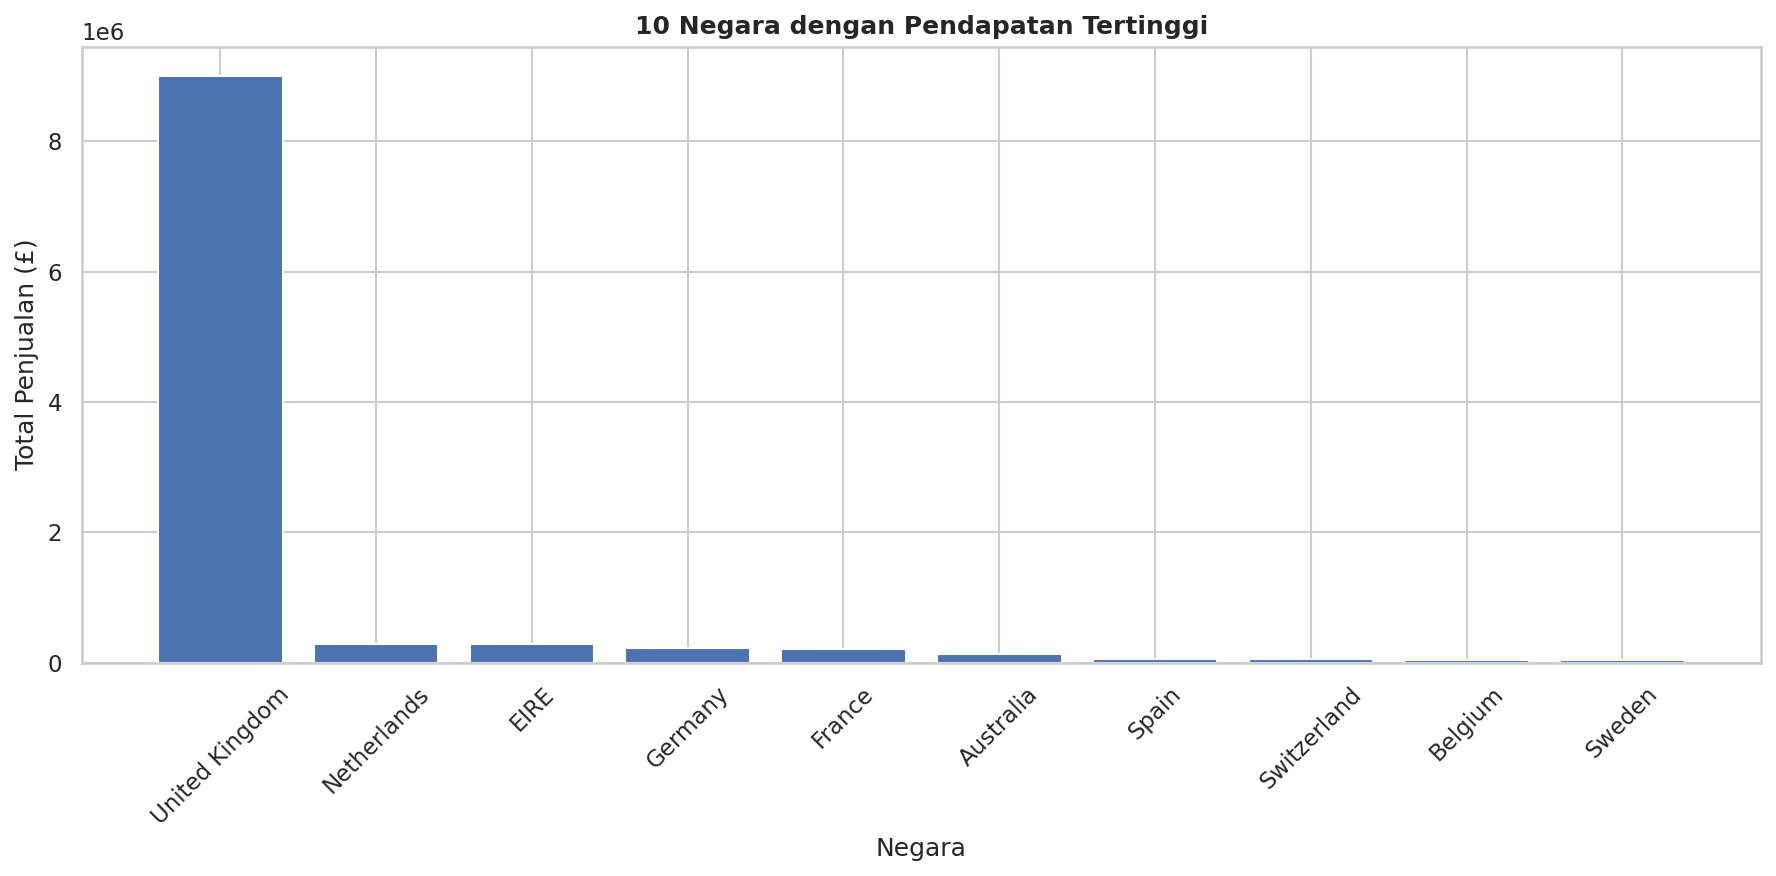

In [61]:
top_country = Country_Sales.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_country["Country"],
    top_country["SalesAmount"]
)

plt.title("10 Negara dengan Pendapatan Tertinggi")
plt.xlabel("Negara")
plt.ylabel("Total Penjualan (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

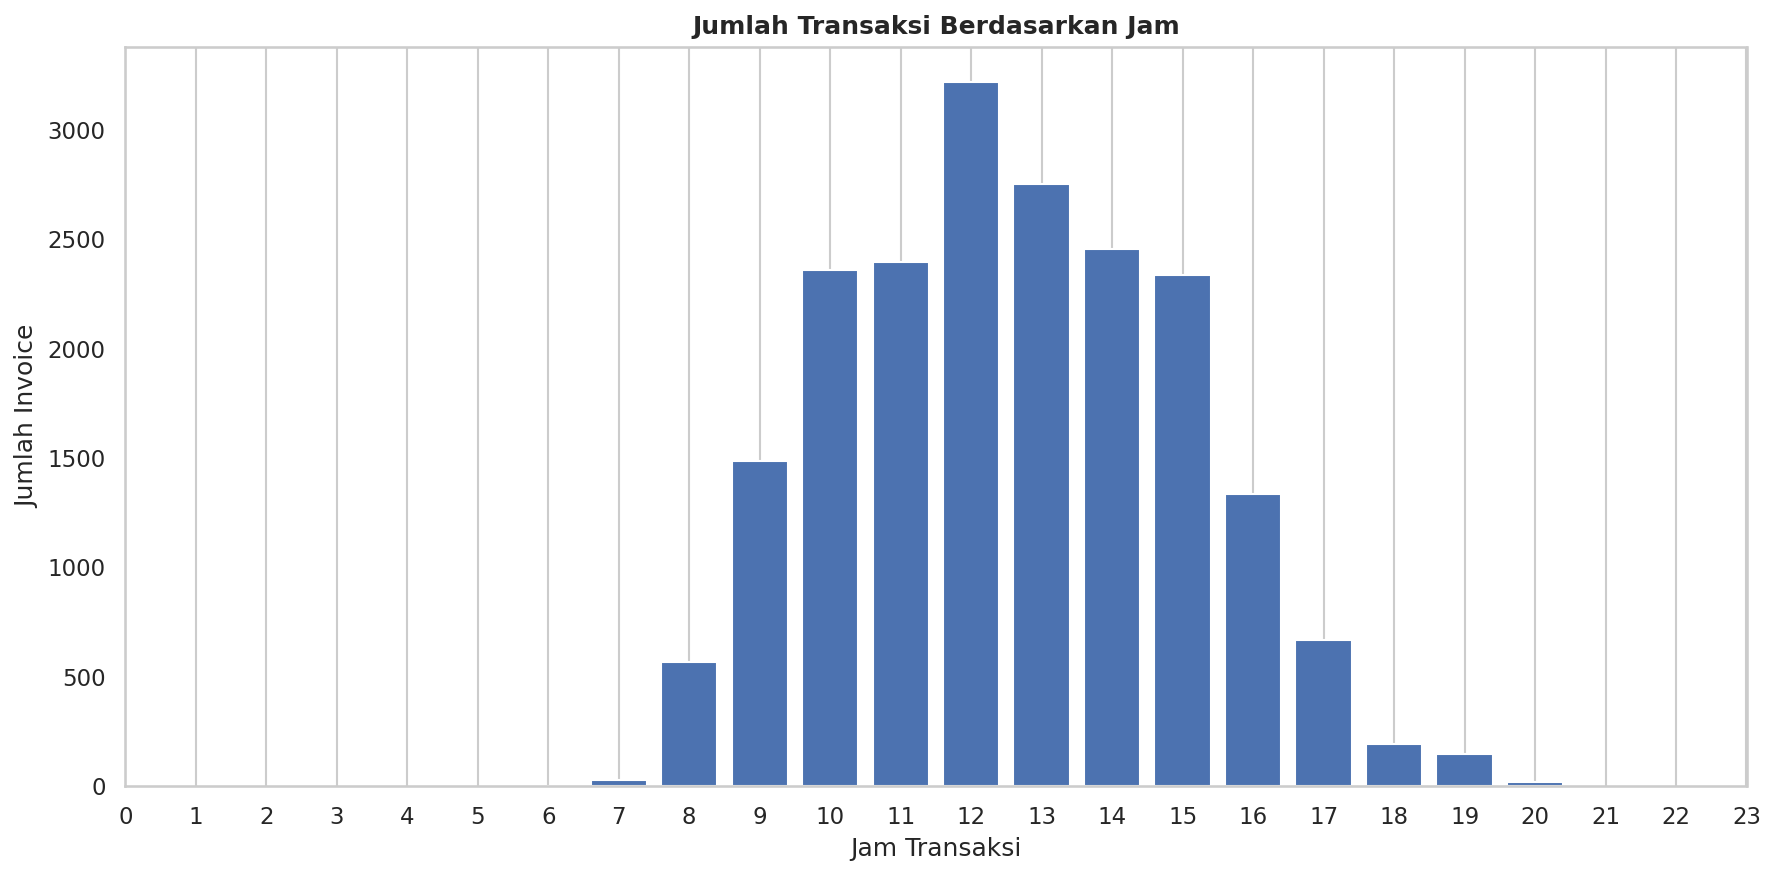

In [63]:
plt.figure(figsize=(12, 6))

plt.bar(
    Hourly_Sales["Hour"],
    Hourly_Sales["Total_Transactions"]
)

plt.title("Jumlah Transaksi Berdasarkan Jam")
plt.xlabel("Jam Transaksi")
plt.ylabel("Jumlah Invoice")
plt.xticks(range(0, 24))
plt.grid(axis="y")

plt.tight_layout()
plt.show()

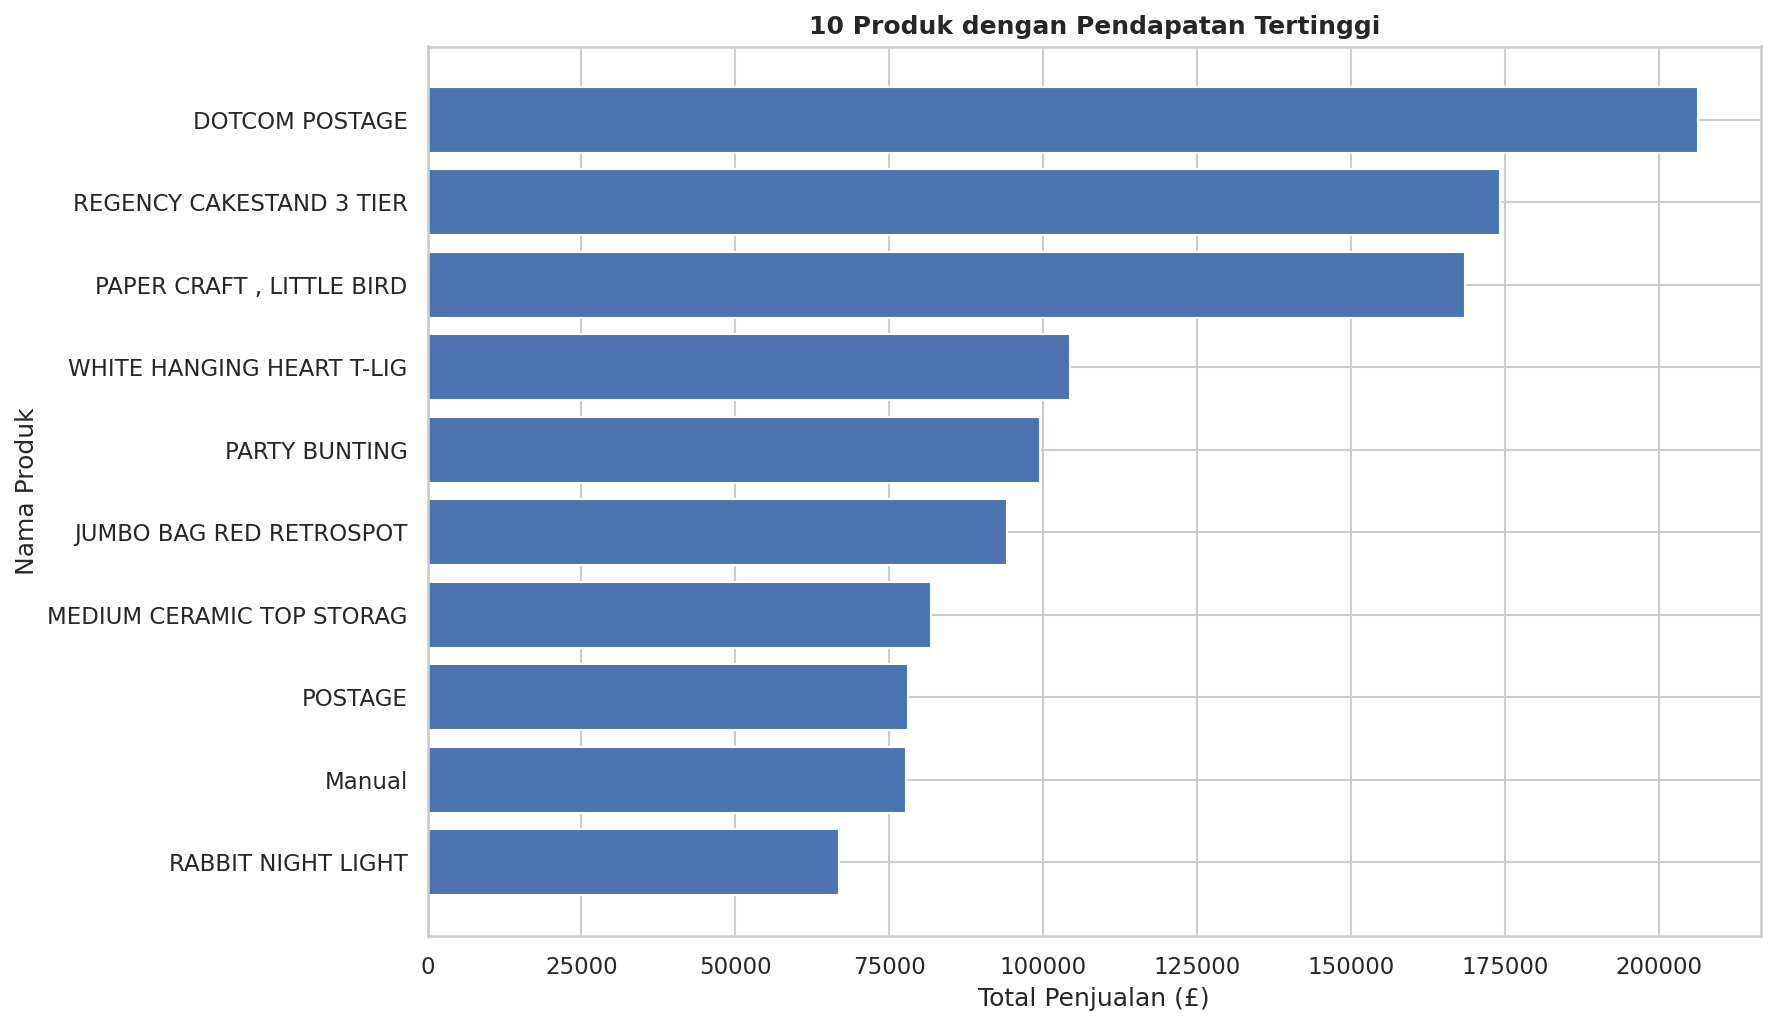

In [64]:
top_product = Product_Sales.head(10).copy()

top_product["ProductName"] = (
    top_product["Description"].str.slice(0, 25)
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_product["ProductName"][::-1],
    top_product["SalesAmount"][::-1]
)

plt.title("10 Produk dengan Pendapatan Tertinggi")
plt.xlabel("Total Penjualan (£)")
plt.ylabel("Nama Produk")

plt.tight_layout()
plt.show()

**Interpretasi Hasil dan Temuan Bisnis**

In [65]:
best_month = Monthly_Sales.loc[
    Monthly_Sales["SalesAmount"].idxmax()
]

print("Bulan dengan Pendapatan Tertinggi:")
print("Periode:", best_month["YearMonth"])
print("Pendapatan: £", round(best_month["SalesAmount"], 2))

Bulan dengan Pendapatan Tertinggi:
Periode: 2011-11
Pendapatan: £ 1503866.78


In [66]:
best_country = Country_Sales.iloc[0]

print("Negara dengan Pendapatan Tertinggi:")
print("Negara:", best_country["Country"])
print("Pendapatan: £", round(best_country["SalesAmount"], 2))

Negara dengan Pendapatan Tertinggi:
Negara: United Kingdom
Pendapatan: £ 9001744.09


In [67]:
best_hour = Hourly_Sales.loc[
    Hourly_Sales["Total_Transactions"].idxmax()
]

print("Jam Transaksi Terbanyak:")
print("Jam:", best_hour["Hour"], ":00")
print("Jumlah Invoice:", best_hour["Total_Transactions"])

Jam Transaksi Terbanyak:
Jam: 12 :00
Jumlah Invoice: 3220


In [68]:
best_product = Product_Sales.iloc[0]

print("Produk dengan Pendapatan Tertinggi:")
print("Nama Produk:", best_product["Description"])
print("Stock Code:", best_product["StockCode"])
print("Pendapatan: £", round(best_product["SalesAmount"], 2))

Produk dengan Pendapatan Tertinggi:
Nama Produk: DOTCOM POSTAGE
Stock Code: DOT
Pendapatan: £ 206248.77


In [69]:
print("RINGKASAN TEMUAN BISNIS")
print("=" * 40)

print("Total Pendapatan: £",
      round(Fact_Sales["SalesAmount"].sum(), 2))

print("Periode Pendapatan Tertinggi:",
      best_month["YearMonth"])

print("Negara Pendapatan Tertinggi:",
      best_country["Country"])

print("Jam Transaksi Tertinggi:",
      best_hour["Hour"], ":00")

print("Produk Pendapatan Tertinggi:",
      best_product["Description"])

RINGKASAN TEMUAN BISNIS
Total Pendapatan: £ 10642110.8
Periode Pendapatan Tertinggi: 2011-11
Negara Pendapatan Tertinggi: United Kingdom
Jam Transaksi Tertinggi: 12 :00
Produk Pendapatan Tertinggi: DOTCOM POSTAGE


**Hasil Analisis dan Temuan**
Berdasarkan hasil analisis, penjualan tertinggi terjadi pada November 2011 dengan total pendapatan sebesar £1,503,866.78. United Kingdom menjadi negara dengan pendapatan terbesar, yaitu £9,001,744.09. Aktivitas transaksi paling tinggi terjadi pada pukul 12.00. Sementara itu, produk dengan nilai penjualan tertinggi adalah DOTCOM POSTAGE yang merupakan layanan pengiriman.

**Rekomendasi dan Kesimpulan**
Berdasarkan hasil analisis, perusahaan disarankan untuk mempersiapkan stok sebelum periode penjualan tertinggi, mempertahankan pelanggan di United Kingdom, serta mengoptimalkan pelayanan pada jam transaksi yang ramai. Analisis layanan pengiriman juga sebaiknya dipisahkan dari produk fisik agar hasil analisis lebih akurat.

Secara keseluruhan, proses pengolahan data Online Retail berhasil menghasilkan data warehouse menggunakan skema Star Schema. Data tersebut dapat digunakan untuk memahami pola penjualan dan membantu perusahaan mengambil keputusan bisnis berdasarkan informasi yang tersedia.